<a href="https://colab.research.google.com/github/KishanSadeesh/DataScience/blob/main/DBSCAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np


In [5]:
data = pd.read_csv("Sleep_health_and_lifestyle_dataset-selected-columns.csv")
data

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
0,27,6.1,6,42,6,77,4200
1,28,6.2,6,60,8,75,10000
2,28,6.2,6,60,8,75,10000
3,28,5.9,4,30,8,85,3000
4,28,5.9,4,30,8,85,3000
...,...,...,...,...,...,...,...
369,59,8.1,9,75,3,68,7000
370,59,8.0,9,75,3,68,7000
371,59,8.1,9,75,3,68,7000
372,59,8.1,9,75,3,68,7000


In [6]:
data.isnull().sum()

,0
Age,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
Heart Rate,0
Daily Steps,0


In [7]:
data.dropna(inplace=True)
data.drop_duplicates(inplace=True)


In [8]:
X = data

In [14]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data)
dbscan = DBSCAN(
    eps=0.3,
    min_samples=4
)

In [15]:
clusters = dbscan.fit_predict(X_scaled)

In [17]:
data["Cluster"] = clusters
print("\nCluster Summary")
print(data["Cluster"].value_counts())


Cluster Summary
Cluster
-1    43
 0    10
 8     8
 7     8
 5     7
 9     6
 1     5
 2     5
 4     5
 6     5
 3     4
Name: count, dtype: int64


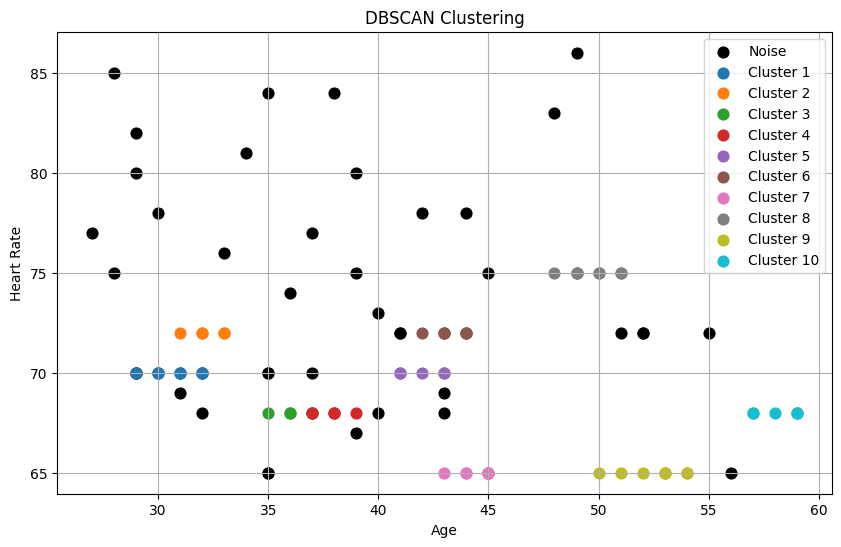

In [22]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))

for cluster in sorted(data["Cluster"].unique()):

    cluster_data = data[
        data["Cluster"] == cluster
    ]

    if cluster == -1:

        plt.scatter(
            cluster_data["Age"],
            cluster_data["Heart Rate"],
            color="black",
            label="Noise",
            s=60
        )

    else:

        plt.scatter(
            cluster_data["Age"],
            cluster_data["Heart Rate"],
            label=f"Cluster {cluster+1}",
            s=60
        )

plt.xlabel("Age")
plt.ylabel("Heart Rate")

plt.title("DBSCAN Clustering")

plt.legend()
plt.grid(True)

plt.show()